# What we built and what it did

TabICL v2's released table stages, fine-tuned, with an image side trained from scratch on generated tables where every row also carries a real photo. The photo is encoded by frozen DINOv2 (block 4 patch tokens); the image side reads it against the 32 nearest context photos and their labels. This notebook shows one training task, walks one batch through the model, and plots the results that decided things. Numbers come from the files in `results/`.

In [1]:
import os, sys, json
os.chdir(next(p for p in [os.getcwd(), os.path.dirname(os.getcwd())] if os.path.exists(os.path.join(p, "table_image_icl"))))
sys.path.insert(0, os.getcwd())
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt

OUT = "assets/results"
os.makedirs(OUT, exist_ok=True)
torch.manual_seed(0); np.random.seed(0)

def record(run, name):
    return json.load(open(f"results/{run}/{name}"))

## 1. One training task

A table from TabICL v2's prior. One column is hidden and shown only through the photo: its value picks the photo's class. So the photo carries information the table lost, and the model can only get it back by reading the photo.

columns kept: 7 | hidden column values: [-1.08  2.47  0.18 -0.55  0.41  0.18] | bins: [0 2 2 1 2 2]


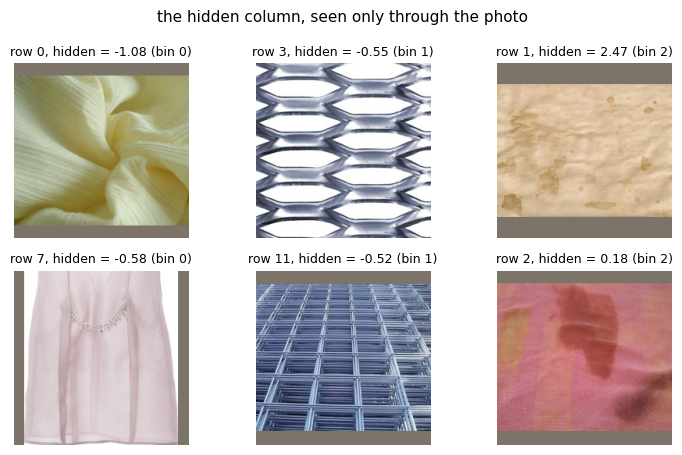

In [2]:
from table_image_icl.collections import load_collection
from table_image_icl.tasks import TaskConfig, task_batches

collections = {name: load_collection(name, max_images=600) for name in ["eurosat", "dtd"]}
cfg = TaskConfig(batch_size=2, rows=(40, 56), features=(4, 8), max_classes=4, max_bins=3, image_as_label_share=0.0)
batch = next(task_batches(cfg, collections, seed=1))
t = 0
c = collections[batch.collection[t]]
print("columns kept:", int(batch.n_columns[t]), "| hidden column values:", batch.hidden[t, :6].numpy().round(2), "| bins:", batch.bins[t, :6].numpy())

fig, axes = plt.subplots(2, 3, figsize=(7.5, 4.6))
for k in range(3):
    for i, r in enumerate(np.where(batch.bins[t].numpy() == k)[0][:2]):
        idx = int(batch.image_index[t, r])
        axes[i, k].imshow(c["images"][idx]); axes[i, k].axis("off")
        axes[i, k].set_title(f"row {r}, hidden = {batch.hidden[t, r]:.2f} (bin {k})", fontsize=9)
fig.suptitle("the hidden column, seen only through the photo", fontsize=11)
fig.tight_layout(); fig.savefig(f"{OUT}/task.png", dpi=160, bbox_inches="tight")

## 2. The model, one batch at a time

Four stages; three are TabICL v2's, pretrained on about 82M tables and fine-tuned here at a small learning rate. Column stage: each column's cells attend to each other, so a cell knows its column's distribution. Image side (ours, trained from scratch): the frozen DINOv2 patches of a row go through a small encoder, then a labelled read where they attend to the patches of the 32 nearest context photos and read their labels. Row stage: a row's cells and its patches attend to each other and are pooled into one token. In-context stage: rows attend to rows, test rows read the context labels and score the classes. The released weights are loaded from `checkpoints/block4`.

In [3]:
from table_image_icl.model import load_run
from table_image_icl.tables import contiguous_codes, prepare_table
from table_image_icl.tasks import Tasks
from table_image_icl.inputs import inputs_for

model, config = load_run("checkpoints/block4")
for name, module in model.named_children():
    print(f"{name:13s} {sum(p.numel() for p in module.parameters()) / 1e6:6.2f}M", "(TabICL v2, pretrained)" if name == "table" else "(ours)")

tasks = Tasks(cfg, collections, ["eurosat"], ["dtd"], inputs_for("dino", "cpu", block=config["dino_block"]))
inputs = tasks.inputs(batch, "cpu", "image")
n_context = inputs["y_context"].shape[1]
codes, slots = contiguous_codes(inputs["y_context"])                                # TabICL wants classes numbered 0..k-1
with torch.no_grad():
    cells = model.table.col_embedder._train_forward(prepare_table(inputs["x"], n_context), codes, None, False); print("column stage ", tuple(cells.shape))
    patches = model.photo_tokens(inputs["images"], inputs["y_context"]);                                         print("image side   ", tuple(patches.shape))
    rows = model.table.row_interactor._train_forward(torch.cat([cells, patches], 2), None);                      print("row stage    ", tuple(rows.shape))
    logits = model.table.icl_predictor._icl_predictions(rows, codes)[:, n_context:];                             print("in-context   ", tuple(logits.shape))
    log_probs = model(inputs["x"], inputs["y_context"], images=inputs["images"]);                                print("output       ", tuple(log_probs.shape), "(log-probabilities over the label slots)")
acc = (log_probs[t].argmax(-1) == batch.y_test[t]).float().mean().item()
print(f"accuracy on this task's test rows: {acc:.2f}")

table          27.55M (TabICL v2, pretrained)
embed           0.10M (ours)
encoder         0.56M (ours)
read            0.27M (ours)


Using cache found in /Users/dennisloevlie/.cache/torch/hub/facebookresearch_dinov2_7764ea0f912e53c92e82eb78a2a1631e92725fc8
/Users/dennisloevlie/.cache/torch/hub/facebookresearch_dinov2_7764ea0f912e53c92e82eb78a2a1631e92725fc8/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/Users/dennisloevlie/.cache/torch/hub/facebookresearch_dinov2_7764ea0f912e53c92e82eb78a2a1631e92725fc8/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/Users/dennisloevlie/.cache/torch/hub/facebookresearch_dinov2_7764ea0f912e53c92e82eb78a2a1631e92725fc8/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


column stage  (2, 45, 11, 128)


image side    (2, 45, 256, 128)
row stage     (2, 45, 512)
in-context    (2, 5, 10)


output        (2, 5, 10) (log-probabilities over the label slots)
accuracy on this task's test rows: 1.00


## 3. Did it learn to use the photo?

The model is scored on 400 fixed tasks whose photos come from collections it never trained on, shown four ways: the table alone, the table with each row's photo, the table with the hidden column handed back as a plain column, and the table with each row given another row's photo. Test accuracy, averaged over the tasks. The last view is a control: if the model only liked having extra tokens, it would score as well there as with the right photo.

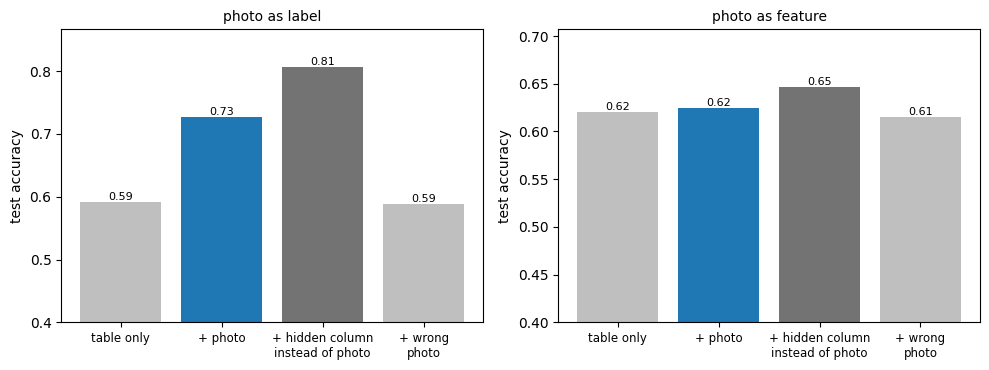

In [4]:
e = record("block4", "evaluation.json")["by_role"]
views = ["no image", "image", "column visible", "images shuffled"]
names = ["table only", "+ photo", "+ hidden column\ninstead of photo", "+ wrong\nphoto"]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, role in zip(axes, ["label", "feature"]):
    acc = [e[role]["views"][v]["accuracy"] for v in views]
    bars = ax.bar(names, acc, color=["0.75", "C0", "0.45", "0.75"])
    for b, a in zip(bars, acc):
        ax.text(b.get_x() + b.get_width() / 2, a, f"{a:.2f}", ha="center", va="bottom", fontsize=8)
    ax.set_title(f"photo as {role}", fontsize=10); ax.set_ylabel("test accuracy"); ax.tick_params(axis="x", labelsize=8.5)
    ax.set_ylim(0.4, max(acc) + 0.06)
fig.tight_layout(); fig.savefig(f"{OUT}/views.png", dpi=160, bbox_inches="tight")

The photo lifts accuracy and the wrong photo does not, so the model reads the photo. A photo that stands in for the label is read well, most of the way to seeing the column itself; a photo that stands in for a feature barely helps.

## 4. Real data

MulTaBench's four validation datasets, 256 labelled rows as context, no training on the data. They are from the benchmark's extended slice: OASIS (one axial MRI slice and demographics, 436 rows), HAM10000 (dermoscopy, 7 classes), PAD-UFES-20 (smartphone lesion photo and 22 clinical features, 6 classes) and SoCal Houses (listing photo and 6 features, price). The reference is TabPFN v2 fed the table plus a PCA of frozen DINOv2 features: the same photo information, a strong table learner.

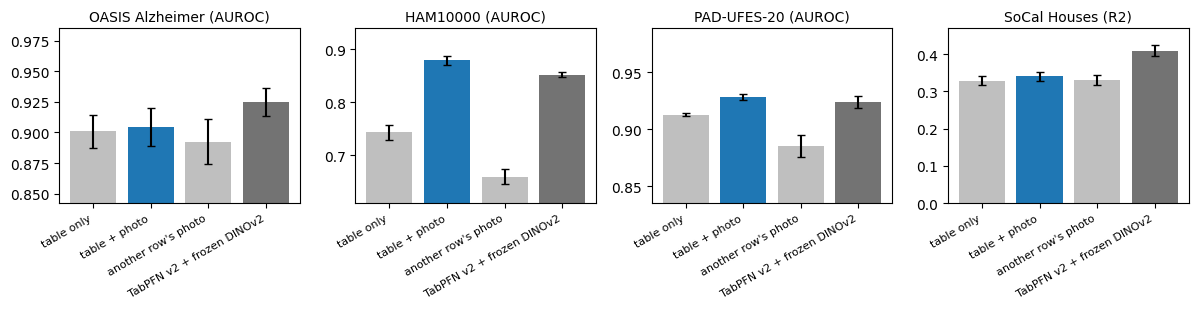

In [5]:
m = record("block4", "multabench.json")["datasets"]
keys = ["ours, table only", "ours, table + image", "ours, image of another row", "TabPFN v2, table + frozen DINOv2 PCA"]
names = ["table only", "table + photo", "another row's photo", "TabPFN v2 + frozen DINOv2"]

fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
for ax, (ds, d) in zip(axes, m.items()):
    means = [d[k]["mean"] for k in keys]; ses = [d[k]["se"] for k in keys]
    ax.bar(range(4), means, yerr=ses, color=["0.75", "C0", "0.75", "0.45"], capsize=3)
    ax.set_xticks(range(4)); ax.set_xticklabels(names, rotation=30, ha="right", fontsize=8)
    ax.set_title(f"{ds} ({d['metric']})", fontsize=10)
    lo = min(means) - 0.05 if d["metric"] == "AUROC" else min(0, min(means) - 0.05)
    ax.set_ylim(lo, max(means) + 0.06)
fig.tight_layout(); fig.savefig(f"{OUT}/realdata.png", dpi=160, bbox_inches="tight")

On HAM10000 the photo adds 0.14 AUROC and on PAD-UFES-20 0.02, with no training on the data, and the model is ahead of the frozen-feature reference on both. On OASIS the photo adds nothing for the model while the reference gains 0.04 from it. On the regression set the reference is ahead with or without the photo.

## 5. The ablation that mattered: which DINOv2 block

Every arm shares the table side (TabICL v2's stages, learning rate 1e-5) and the image-side setting (top-k 32 reads, 25k steps, seed 0). Only what the image side receives differs: frozen DINOv2 patch tokens from block 4, 8 or 12, DINOv2's final CLS and register tokens, or raw pixels through one linear layer trained from scratch (grey).

Deeper, more semantic DINOv2 features win on generated tasks and lose on the real data; the ordering on the medical sets is the reverse of the ordering on generated photos. The from-scratch arm is the extreme case: the weakest on generated tasks and the best on HAM10000 and OASIS, level with block 4 on PAD-UFES-20 and SoCal Houses. The reference lines on the real-data panels are TabPFN v2 on the table alone (dashed) and TabPFN v2 on the table plus 30 PCA components of frozen DINOv2 final features (dotted), both at the same 256 context rows.

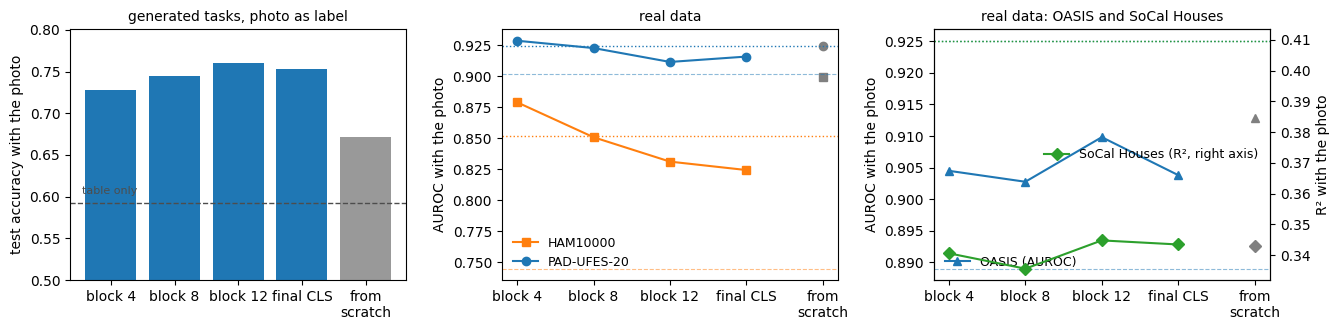

In [6]:
arms = {"block 4": "block4", "block 8": "block8", "block 12": "block12", "final CLS": "cls"}
scratch = {"from\nscratch": "pixels"}
KEY = "ours, table + image"
def scores(runs):
    photo = [record(r, "evaluation.json")["by_role"]["label"]["views"]["image"]["accuracy"] for r in runs.values()]
    real = {ds: [record(r, "multabench.json")["datasets"][ds][KEY]["mean"] for r in runs.values()] for ds in ["OASIS Alzheimer", "HAM10000", "PAD-UFES-20", "SoCal Houses"]}
    return photo, real
with_photo, real = scores(arms)
scratch_photo, scratch_real = scores(scratch)
table_only = np.mean([record(r, "evaluation.json")["by_role"]["label"]["views"]["no image"]["accuracy"] for r in (arms | scratch).values()])
ref = record("block4", "multabench.json")["datasets"]

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.4))
axes[0].bar(list(arms), with_photo, color="C0"); axes[0].bar(list(scratch), scratch_photo, color="0.6")
axes[0].axhline(table_only, color="0.3", ls="--", lw=1); axes[0].text(-0.45, table_only + 0.01, "table only", fontsize=8, ha="left", color="0.3")
axes[0].set_ylim(0.5, max(with_photo) + 0.04); axes[0].set_ylabel("test accuracy with the photo"); axes[0].set_title("generated tasks, photo as label", fontsize=10)
for ds, mk, c in [("HAM10000", "s", "C1"), ("PAD-UFES-20", "o", "C0")]:
    axes[1].plot(list(arms), real[ds], mk + "-", color=c, label=ds); axes[1].plot(list(scratch), scratch_real[ds], mk, color="0.5")
    axes[1].axhline(ref[ds]["TabPFN v2, table + frozen DINOv2 PCA"]["mean"], color=c, ls=":", lw=1); axes[1].axhline(ref[ds]["TabPFN v2, table only"]["mean"], color=c, ls="--", lw=0.8, alpha=0.5)
axes[1].set_ylabel("AUROC with the photo"); axes[1].legend(frameon=False, fontsize=9); axes[1].set_title("real data", fontsize=10)
axes[2].plot(list(arms), real["OASIS Alzheimer"], "^-", color="C0", label="OASIS (AUROC)"); axes[2].plot(list(scratch), scratch_real["OASIS Alzheimer"], "^", color="0.5")
axes[2].axhline(ref["OASIS Alzheimer"]["TabPFN v2, table + frozen DINOv2 PCA"]["mean"], color="C0", ls=":", lw=1); axes[2].axhline(ref["OASIS Alzheimer"]["TabPFN v2, table only"]["mean"], color="C0", ls="--", lw=0.8, alpha=0.5)
axes[2].set_ylabel("AUROC with the photo"); axes[2].legend(frameon=False, fontsize=9, loc="lower left")
ax2 = axes[2].twinx(); ax2.plot(list(arms), real["SoCal Houses"], "D-", color="C2", label="SoCal Houses (R², right axis)"); ax2.plot(list(scratch), scratch_real["SoCal Houses"], "D", color="0.5")
ax2.axhline(ref["SoCal Houses"]["TabPFN v2, table + frozen DINOv2 PCA"]["mean"], color="C2", ls=":", lw=1); ax2.set_ylabel("R² with the photo"); ax2.legend(frameon=False, fontsize=9, loc="center right")
axes[2].set_title("real data: OASIS and SoCal Houses", fontsize=10)
fig.tight_layout(); fig.savefig(f"{OUT}/depth.png", dpi=160, bbox_inches="tight")

## 6. More context rows, no retraining

The model was trained on tables of 64 to 256 rows. Scoring it with more context rows costs nothing but inference: the source cap of the labelled read is raised to match, and the in-context stage extrapolates. The frozen reference gets the same rows each time. MulTaBench caps the training side of a split at 10,000 rows and most datasets have fewer, so each line stops where its data stops. This sweep was run on the development sets, the three core datasets looked at before the validation set moved to the extended slice, plus HAM10000; Mango Mass (364 rows) is left out. The lines are the model with frozen block-4 tokens and the same with raw pixels.

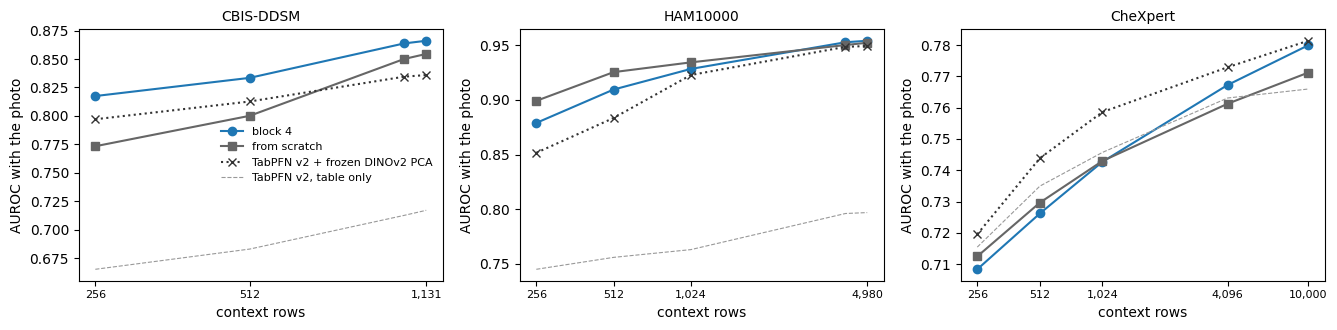

In [7]:
lines = {"block 4": ("block4", "C0", "o"), "from scratch": ("pixels", "0.4", "s")}
SIZES = [256, 512, 1024, 4096, 10000]
def sweep(run, ds, key=KEY):
    points = {}
    for n in SIZES:
        path = f"results/{run}/multabench-development{'' if n == 256 else f'-context{n}'}.json"
        if os.path.exists(path):
            d = json.load(open(path))["datasets"][ds]; points[d["context_rows"]] = d[key]["mean"]
    return sorted(points.items())
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.4))
for ax, ds in zip(axes, ["CBIS-DDSM", "HAM10000", "CheXpert"]):
    for name, (run, color, mk) in lines.items():
        pts = sweep(run, ds)
        if pts:
            ax.plot(*zip(*pts), mk + "-", color=color, label=name)
    pts = sweep("block4", ds, "TabPFN v2, table + frozen DINOv2 PCA"); ax.plot(*zip(*pts), "x:", color="0.2", label="TabPFN v2 + frozen DINOv2 PCA")
    pts = sweep("block4", ds, "TabPFN v2, table only"); ax.plot(*zip(*pts), "--", color="0.6", lw=0.8, label="TabPFN v2, table only")
    ax.set_xscale("log"); ax.set_xlabel("context rows"); ax.set_title(ds, fontsize=10); ax.set_ylabel("AUROC with the photo")
    shown = sorted({x for run, _, _ in lines.values() for x, _ in sweep(run, ds)}); shown = [x for i, x in enumerate(shown) if i == len(shown) - 1 or shown[i + 1] > 1.3 * x]; ax.set_xticks(shown); ax.set_xticklabels([f"{x:,}" for x in shown], fontsize=8); ax.minorticks_off()
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(f"{OUT}/context.png", dpi=160, bbox_inches="tight")

Both arms extrapolate to 16 to 40 times their training context and keep improving. The lead over the frozen reference is largest at 256 to 1,024 rows and the methods meet at the largest contexts, where the table-only view and TabPFN v2 meet too. The photo's advantage for in-context reading is a few-shot advantage.

## 7. The five arms, in one table

The numbers behind section 5. Test accuracy on the 400 generated tasks with the photo (and, for reference, without it), then the four validation sets with the photo.

In [8]:
rows = []
for name, r in (arms | scratch).items():
    e = record(r, "evaluation.json")["by_role"]; m = record(r, "multabench.json")["datasets"]
    rows.append([name.replace("\n", " "), round(e["label"]["views"]["no image"]["accuracy"], 3), round(e["label"]["views"]["image"]["accuracy"], 3),
                 round(e["feature"]["views"]["image"]["accuracy"], 3)] + [round(m[ds][KEY]["mean"], 3) for ds in ["OASIS Alzheimer", "HAM10000", "PAD-UFES-20", "SoCal Houses"]])
pd.DataFrame(rows, columns=["arm", "table only", "with photo (as label)", "with photo (as feature)", "OASIS AUROC", "HAM AUROC", "PAD AUROC", "SoCal R²"]).set_index("arm")

,table only,with photo (as label),with photo (as feature),OASIS AUROC,HAM AUROC,PAD AUROC,SoCal R²
arm,,,,,,,
block 4,0.591,0.728,0.624,0.904,0.879,0.929,0.341
block 8,0.591,0.745,0.632,0.903,0.851,0.923,0.336
block 12,0.594,0.761,0.631,0.910,0.831,0.911,0.345
final CLS,0.593,0.753,0.635,0.904,0.824,0.916,0.343
from scratch,0.595,0.672,0.621,0.913,0.899,0.925,0.343


What we take from this: the model learns to read a photo in context, on HAM10000 and PAD-UFES-20 it is ahead of frozen features plus TabPFN v2 at 256 context rows, and real-data numbers are the ones to trust, since gains on generated tasks (deeper blocks) did not carry over. The in-context stage inherited from TabICL v2 is what lets the model use far more context rows than it was trained on.